**Objective**: In this lab, you will implement and compare manual grid search with scikit-learn's built-in `GridSearchCV` and `RandomizedSearchCV` for hyperparameter tuning. You'll work with multiple classification algorithms and combine them using voting classifiers.

**Learning Goals**:
- Understand hyperparameter tuning through exhaustive and randomized search.
- Compare manual implementation with built-in functions.
- Analyze the impact of feature scaling (`StandardScaler` vs `MinMaxScaler`) on distance-based vs. tree-based models.
- Create and evaluate voting classifiers.
- Visualize model performance using ROC curves and confusion matrices.

**Datasets Used**:
1. Wine Quality - Predicting wine quality based on chemical properties
2. HR Attrition - Predicting employee turnover
3. Banknote Authentication - Detecting counterfeit banknotes
4. QSAR Biodegradation - Predicting chemical biodegradability


## Part 1: Import Libraries and Setup

First, let's import all the necessary libraries for our machine learning pipeline.

In [ ]:
import pandas as pd
import numpy as np
import itertools
import time
import matplotlib.pyplot as plt
from scipy.stats import randint
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
# Bypass SSL certificate verification for dataset downloads
import ssl
ssl._create_default_https_context = ssl._create_unverified_context

# Models and Parameter Grids

Here we define the classifiers we'll tune and their respective hyperparameter grids. Notice how the parameter names include the pipeline step prefix (e.g., 'classifier__max_depth').

In [ ]:
param_grid_dt = {
    'scaler': [StandardScaler(), MinMaxScaler()],
    'feature_selection__k': [8, 10, 'all'],
    'classifier__criterion': ['gini', 'entropy'],
    'classifier__max_depth': [3, 5, 6],
    'classifier__min_samples_leaf': [3, 5]
}

param_grid_knn = {
    'scaler': [StandardScaler(), MinMaxScaler()],
    'feature_selection__k': [8, 10, 'all'],
    'classifier__n_neighbors': [3, 5, 7],
    'classifier__weights': ['distance'],
    'classifier__metric': ['euclidean', 'manhattan']
}

classifiers_to_tune = [
    (DecisionTreeClassifier(random_state=42), param_grid_dt, 'Decision Tree'),
    (KNeighborsClassifier(), param_grid_knn, 'K-Nearest Neighbors')
]

## Dataset Loading Functions
We'll work with four different datasets to test our algorithms across various domains.

### 3.1 Wine Quality Dataset


In [ ]:
def load_wine_quality():
    """Load Wine Quality dataset"""
    url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv'
    try:
        data = pd.read_csv(url, sep=';')
    except Exception as e:
        print(f"Error loading Wine Quality dataset: {e}")
        return None, None, None, None, "Wine Quality (Failed)"
    data['good_quality'] = (data['quality'] > 5).astype(int)
    X = data.drop(['quality', 'good_quality'], axis=1)
    y = data['good_quality']
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
    print("Wine Quality dataset loaded and preprocessed successfully.")
    print(f"Training set shape: {X_train.shape}")
    return X_train, X_test, y_train, y_test, "Wine Quality"

### 3.2 HR Attrition Dataset


In [ ]:
def load_hr_attrition():
    """Load IBM HR Attrition dataset"""
    try:
        data = pd.read_csv("/content/WA_Fn-UseC_-HR-Employee-Attrition.csv")
    except FileNotFoundError:
        print("HR Attrition dataset not found.")
        return None, None, None, None, "HR Attrition (Failed)"
    data['Attrition'] = (data['Attrition'] == 'Yes').astype(int)
    X = data.drop(['EmployeeNumber', 'Attrition'], axis=1, errors='ignore')
    y = data['Attrition']
    X = pd.get_dummies(X, drop_first=True)
    X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.3, random_state=42)
    return X_train, X_test, y_train, y_test, "HR Attrition"

### 3.3 Banknote Authentication Dataset


In [ ]:
def load_banknote():
    """Load Banknote Authentication dataset"""
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00267/data_banknote_authentication.txt"
    try:
        data = pd.read_csv(url, header=None)
    except Exception as e:
        return None, None, None, None, "Banknote (Failed)"
    X = data.iloc[:, :-1]
    y = data.iloc[:, -1]
    X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.3, random_state=42)
    return X_train, X_test, y_train, y_test, "Banknote Authentication"

### 3.4 QSAR Biodegradation Dataset


In [ ]:
def load_qsar_biodegradation():
    """Load QSAR Biodegradation dataset"""
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00254/biodeg.csv"
    try:
        data = pd.read_csv(url, sep=';', header=None)
    except Exception as e:
        return None, None, None, None, "QSAR (Failed)"
    X = data.iloc[:, :-1]
    y = (data.iloc[:, -1] == 'RB').astype(int)
    X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.3, random_state=42)
    return X_train, X_test, y_train, y_test, "QSAR Biodegradation"

## Part 4: Manual Grid Search Implementation


In [ ]:
def run_manual_grid_search(X_train, y_train, dataset_name):
    """Run manual grid search and return best estimators"""
    print(f"\n{'='*60}")
    print(f"RUNNING MANUAL GRID SEARCH FOR {dataset_name.upper()}")
    print(f"{'='*60}")

    best_estimators = {}
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    n_features = X_train.shape[1]

    for classifier_instance, param_grid, name in classifiers_to_tune:
        print(f"\n--- Tuning {name} ---")
        best_score = -1
        best_params = None

        # Adjust feature selection parameter based on dataset features available
        adjusted_param_grid = param_grid.copy()
        if 'feature_selection__k' in adjusted_param_grid:
            k_values = []
            for k in adjusted_param_grid['feature_selection__k']:
                if k == 'all':
                    k_values.append('all')
                elif isinstance(k, int) and k <= n_features:
                    k_values.append(k)
                elif isinstance(k, int):
                    k_values.append(min(k, n_features))
            new_k = []
            for k in k_values:
                if k not in new_k:
                    new_k.append(k)
            adjusted_param_grid['feature_selection__k'] = new_k

        keys, values = zip(*adjusted_param_grid.items())
        param_combinations = [dict(zip(keys, v)) for v in itertools.product(*values)]

        # Cross-validation loop
        for params in param_combinations:
            fold_auc_scores = []
            for train_idx, val_idx in cv.split(X_train, y_train):
                X_train_fold, X_val_fold = X_train.iloc[train_idx], X_train.iloc[val_idx]
                y_train_fold, y_val_fold = y_train.iloc[train_idx], y_train.iloc[val_idx]

                # The scalar step will be safely overwritten by .set_params if included in params
                pipeline = Pipeline(steps=[
                    ('scaler', StandardScaler()),
                    ('feature_selection', SelectKBest(f_classif)),
                    ('classifier', classifier_instance)
                ])
                pipeline.set_params(**params)
                pipeline.fit(X_train_fold, y_train_fold)
                y_pred_proba_fold = pipeline.predict_proba(X_val_fold)[:, 1]
                fold_auc = roc_auc_score(y_val_fold, y_pred_proba_fold)
                fold_auc_scores.append(fold_auc)

            mean_auc = np.mean(fold_auc_scores)
            if mean_auc > best_score:
                best_score = mean_auc
                best_params = params

        print("-" * 90)
        print(f"Best parameters for {name}: {best_params}")
        print(f"Best cross-validation AUC: {best_score:.4f}")

        # Create the final pipeline
        final_pipeline = Pipeline(steps=[
            ('scaler', StandardScaler()),
            ('feature_selection', SelectKBest(f_classif)),
            ('classifier', classifier_instance)
        ])
        final_pipeline.set_params(**best_params)
        final_pipeline.fit(X_train, y_train)
        best_estimators[name] = final_pipeline

    return best_estimators

**Understanding the Manual Implementation**:
- **Nested Cross-Validation**: For each parameter combination, we perform 5-fold CV
- **Pipeline Integration**: Each step (scaling, feature selection, classification) is properly chained
- **AUC Scoring**: We use Area Under the ROC Curve as our optimization metric
- **Best Model Selection**: The combination with highest mean AUC across folds is selected

## Part 5: Built-in Grid Search Implementation

Now let's compare our manual implementation with scikit-learn's `GridSearchCV`.

**Advantages of Built-in GridSearchCV**:
- **Parallel Processing**: Uses `n_jobs=-1` for faster computation
- **Cleaner Code**: Less verbose than manual implementation
- **Built-in Features**: Automatic best model selection and scoring

In [ ]:
def run_builtin_grid_search(X_train, y_train, dataset_name):
    """Run built-in grid search and return best estimators"""
    print(f"\n{'='*60}")
    print(f"RUNNING BUILT-IN GRID SEARCH FOR {dataset_name.upper()}")
    print(f"{'='*60}")

    results_builtin = {}
    n_features = X_train.shape[1]

    for classifier_instance, param_grid, name in classifiers_to_tune:
        print(f"\n--- GridSearchCV for {name} ---")

        # Feature constraint logic
        adjusted_param_grid = param_grid.copy()
        if 'feature_selection__k' in adjusted_param_grid:
            k_values = []
            for k in adjusted_param_grid['feature_selection__k']:
                if k == 'all':
                    k_values.append('all')
                elif isinstance(k, int) and k <= n_features:
                    k_values.append(k)
                elif isinstance(k, int):
                    k_values.append(min(k, n_features))
            new_k = []
            for k in k_values:
                if k not in new_k:
                    new_k.append(k)
            adjusted_param_grid['feature_selection__k'] = new_k

        # Pipeline structure
        pipeline = Pipeline(steps=[
            ('scaler', StandardScaler()),
            ('feature_selection', SelectKBest(f_classif)),
            ('classifier', classifier_instance)
        ])

        cv_splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
        grid_search = GridSearchCV(
            estimator=pipeline,
            param_grid=adjusted_param_grid,
            scoring='roc_auc',
            cv=cv_splitter,
            n_jobs=-1
        )

        start_time = time.time()
        grid_search.fit(X_train, y_train)
        exec_time = time.time() - start_time

        results_builtin[name] = {
            'best_estimator': grid_search.best_estimator_,
            'best_score (CV)': grid_search.best_score_,
            'best_params': grid_search.best_params_,
            'execution_time': exec_time
        }
        print(f"Execution Time: {exec_time:.2f} seconds")
        print(f"Best params for {name}: {results_builtin[name]['best_params']}")
        print(f"Best CV score: {results_builtin[name]['best_score (CV)']:.4f}")

    return results_builtin

## Part 6: Randomized Search Integration

To evaluate the trade-off between exhaustive search and randomized combinations, we'll implement `RandomizedSearchCV`.

In [ ]:
def run_randomized_search(X_train, y_train, dataset_name):
    """Run randomized search and return best estimators"""
    print(f"\n{'='*60}")
    print(f"RUNNING RANDOMIZED SEARCH FOR {dataset_name.upper()}")
    print(f"{'='*60}")

    results_random = {}
    n_features = X_train.shape[1]

    # Define randomized continuous distributions
    param_dist_dt = {
        'scaler': [StandardScaler(), MinMaxScaler()],
        'feature_selection__k': [k for k in [8, 10, 'all'] if k == 'all' or k <= n_features],
        'classifier__criterion': ['gini', 'entropy'],
        'classifier__max_depth': randint(3, 15),
        'classifier__min_samples_leaf': randint(1, 10)
    }

    param_dist_knn = {
        'scaler': [StandardScaler(), MinMaxScaler()],
        'feature_selection__k': [k for k in [8, 10, 'all'] if k == 'all' or k <= n_features],
        'classifier__n_neighbors': randint(3, 15),
        'classifier__weights': ['uniform', 'distance'],
        'classifier__metric': ['euclidean', 'manhattan']
    }

    classifiers_random = [
        (DecisionTreeClassifier(random_state=42), param_dist_dt, 'Decision Tree'),
        (KNeighborsClassifier(), param_dist_knn, 'K-Nearest Neighbors')
    ]

    for classifier_instance, param_dist, name in classifiers_random:
        print(f"\n--- RandomizedSearchCV for {name} ---")

        pipeline = Pipeline(steps=[
            ('scaler', StandardScaler()),
            ('feature_selection', SelectKBest(f_classif)),
            ('classifier', classifier_instance)
        ])

        cv_splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
        random_search = RandomizedSearchCV(
            estimator=pipeline,
            param_distributions=param_dist,
            n_iter=10,
            scoring='roc_auc',
            cv=cv_splitter,
            random_state=42,
            n_jobs=-1
        )

        start_time = time.time()
        random_search.fit(X_train, y_train)
        exec_time = time.time() - start_time

        results_random[name] = {
            'best_estimator': random_search.best_estimator_,
            'best_score (CV)': random_search.best_score_,
            'best_params': random_search.best_params_,
            'execution_time': exec_time
        }
        print(f"Execution Time: {exec_time:.2f} seconds")
        print(f"Best params for {name}: {results_random[name]['best_params']}")
        print(f"Best CV score: {results_random[name]['best_score (CV)']:.4f}")

    return results_random

## Part 7: Model Evaluation and Voting Classifiers

This function evaluates individual models and creates voting classifiers to combine their predictions.

In [ ]:
def evaluate_models(X_test, y_test, best_estimators, dataset_name, method_name="Manual"):
    """Evaluate models and create visualizations"""
    print(f"\n{'='*60}")
    print(f"EVALUATING {method_name.upper()} MODELS FOR {dataset_name.upper()}")
    print(f"{'='*60}")

    # Individual model evaluation
    print(f"\n--- Individual Model Performance ---")
    for name, model in best_estimators.items():
        y_pred = model.predict(X_test)
        y_pred_proba = model.predict_proba(X_test)[:, 1]
        print(f"\n{name}:")
        print(f"  Accuracy: {accuracy_score(y_test, y_pred):.4f}")
        print(f"  Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
        print(f"  Recall: {recall_score(y_test, y_pred, zero_division=0):.4f}")
        print(f"  F1-Score: {f1_score(y_test, y_pred, zero_division=0):.4f}")
        print(f"  ROC AUC: {roc_auc_score(y_test, y_pred_proba):.4f}")

    # Voting Classifier
    print(f"\n--- {method_name} Voting Classifier ---")
    if method_name == "Manual":
        # Manual voting implementation
        y_pred_votes = []
        y_pred_proba_avg = []
        for i in range(len(X_test)):
            votes = []
            probas = []
            for name, model in best_estimators.items():
                pred = model.predict(X_test.iloc[[i]])[0]
                proba = model.predict_proba(X_test.iloc[[i]])[0, 1]
                votes.append(pred)
                probas.append(proba)
            majority_vote = 1 if np.mean(votes) > 0.5 else 0
            avg_proba = np.mean(probas)
            y_pred_votes.append(majority_vote)
            y_pred_proba_avg.append(avg_proba)
        y_pred_votes = np.array(y_pred_votes)
        y_pred_proba_avg = np.array(y_pred_proba_avg)
    else:
        # Built-in Voting Classifier
        estimators = [(name, model) for name, model in best_estimators.items()]
        voting_clf = VotingClassifier(estimators=estimators, voting='soft')
        voting_clf.fit(X_train, y_train)  # Note: This assumes X_train, y_train are globally available
        y_pred_votes = voting_clf.predict(X_test)
        y_pred_proba_avg = voting_clf.predict_proba(X_test)[:, 1]

    if len(y_pred_votes) > 0:
        accuracy = accuracy_score(y_test, y_pred_votes)
        precision = precision_score(y_test, y_pred_votes, zero_division=0)
        recall = recall_score(y_test, y_pred_votes, zero_division=0)
        f1 = f1_score(y_test, y_pred_votes, zero_division=0)
        auc = roc_auc_score(y_test, y_pred_proba_avg)
        print(f"Voting Classifier Performance:")
        print(f"  Accuracy: {accuracy:.4f}, Precision: {precision:.4f}, Recall: {recall:.4f}, F1: {f1:.4f}, AUC: {auc:.4f}")

        # Visualizations (ROC curves and Confusion Matrix)
        plt.figure(figsize=(12, 5))
        plt.subplot(1, 2, 1)
        for name, model in best_estimators.items():
            y_pred_proba_m = model.predict_proba(X_test)[:, 1]
            fpr, tpr, _ = roc_curve(y_test, y_pred_proba_m)
            auc_score = roc_auc_score(y_test, y_pred_proba_m)
            plt.plot(fpr, tpr, label=f'{name} (AUC = {auc_score:.3f})')

        fpr_vote, tpr_vote, _ = roc_curve(y_test, y_pred_proba_avg)
        plt.plot(fpr_vote, tpr_vote, label=f'Voting (AUC = {auc:.3f})', linewidth=3, linestyle='--')
        plt.plot([0, 1], [0, 1], 'k--', label='Chance')
        plt.xlabel('False Positive Rate')
        plt.ylabel('True Positive Rate')
        plt.title(f'ROC Curves - {dataset_name} ({method_name})')
        plt.legend()
        plt.grid(True)

        plt.subplot(1, 2, 2)
        cm = confusion_matrix(y_test, y_pred_votes)
        disp = ConfusionMatrixDisplay(confusion_matrix=cm)
        disp.plot(ax=plt.gca(), cmap="Blues")
        plt.title(f'Voting Classifier - {dataset_name} ({method_name})')
        plt.tight_layout()
        plt.show()

    return y_pred_votes, y_pred_proba_avg

## Part 8: Complete Pipeline Function

This function orchestrates the entire experiment for each dataset.

In [ ]:
def run_complete_pipeline(dataset_loader, dataset_name):
    """Run complete pipeline for a dataset"""
    print(f"\n{'#'*80}")
    print(f"PROCESSING DATASET: {dataset_name.upper()}")
    print(f"{'#'*80}")

    # Make X_train, y_train global so evaluate_models can access them for the voting classifier fit
    global X_train, y_train
    X_train, X_test, y_train, y_test, actual_name = dataset_loader()
    if X_train is None:
        print(f"Skipping {dataset_name} due to loading error.")
        return
    print("-" * 30)

    # Part 1: Manual Implementation
    manual_estimators = run_manual_grid_search(X_train, y_train, actual_name)
    if manual_estimators:
        evaluate_models(X_test, y_test, manual_estimators, actual_name, "Manual")

    # Part 2: Built-in Implementation
    builtin_results = run_builtin_grid_search(X_train, y_train, actual_name)
    if builtin_results:
        builtin_estimators = {name: res['best_estimator'] for name, res in builtin_results.items()}
        evaluate_models(X_test, y_test, builtin_estimators, actual_name, "Built-in")

    # Part 3: Randomized Search Implementation
    random_results = run_randomized_search(X_train, y_train, actual_name)
    if random_results:
        random_estimators = {name: res['best_estimator'] for name, res in random_results.items()}
        evaluate_models(X_test, y_test, random_estimators, actual_name, "Randomized")

    print(f"\nCompleted processing for {actual_name}")
    print("="*80)

## Part 9: Execute the Complete Lab

Now let's run our pipeline on all four datasets!


################################################################################
PROCESSING DATASET: WINE QUALITY
################################################################################
Wine Quality dataset loaded and preprocessed successfully.
Training set shape: (1119, 11)
------------------------------

RUNNING MANUAL GRID SEARCH FOR WINE QUALITY

--- Tuning Decision Tree ---
------------------------------------------------------------------------------------------
Best parameters for Decision Tree: {'scaler': MinMaxScaler(), 'feature_selection__k': 8, 'classifier__criterion': 'entropy', 'classifier__max_depth': 6, 'classifier__min_samples_leaf': 5}
Best cross-validation AUC: 0.7938

--- Tuning K-Nearest Neighbors ---
------------------------------------------------------------------------------------------
Best parameters for K-Nearest Neighbors: {'scaler': StandardScaler(), 'feature_selection__k': 8, 'classifier__n_neighbors': 7, 'classifier__weights': 'distance', 'class

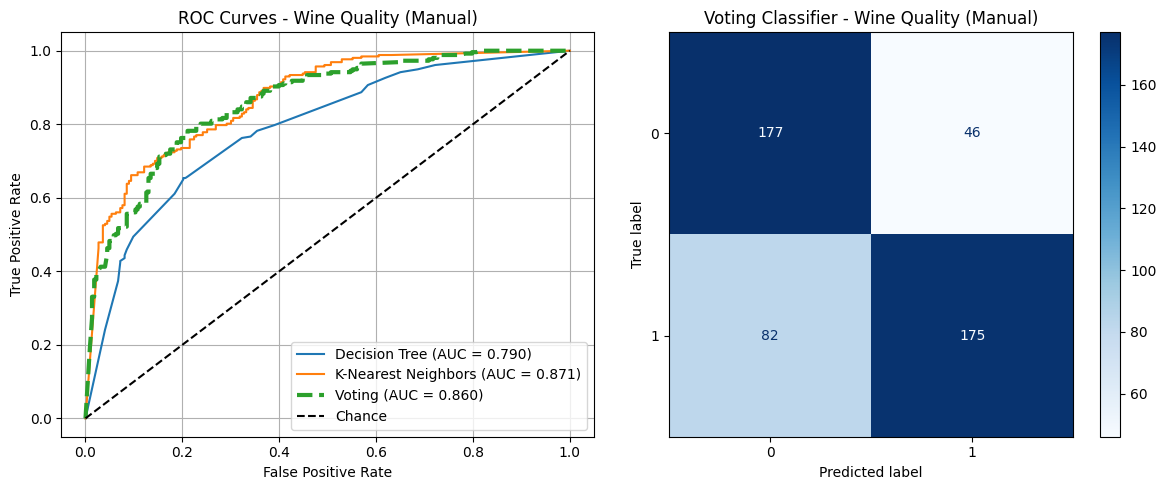


RUNNING BUILT-IN GRID SEARCH FOR WINE QUALITY

--- GridSearchCV for Decision Tree ---
Execution Time: 6.02 seconds
Best params for Decision Tree: {'classifier__criterion': 'entropy', 'classifier__max_depth': 6, 'classifier__min_samples_leaf': 5, 'feature_selection__k': 8, 'scaler': MinMaxScaler()}
Best CV score: 0.7938

--- GridSearchCV for K-Nearest Neighbors ---
Execution Time: 2.43 seconds
Best params for K-Nearest Neighbors: {'classifier__metric': 'manhattan', 'classifier__n_neighbors': 7, 'classifier__weights': 'distance', 'feature_selection__k': 8, 'scaler': StandardScaler()}
Best CV score: 0.8598

EVALUATING BUILT-IN MODELS FOR WINE QUALITY

--- Individual Model Performance ---

Decision Tree:
  Accuracy: 0.7229
  Precision: 0.7313
  Recall: 0.7626
  F1-Score: 0.7467
  ROC AUC: 0.7897

K-Nearest Neighbors:
  Accuracy: 0.7583
  Precision: 0.7621
  Recall: 0.7977
  F1-Score: 0.7795
  ROC AUC: 0.8707

--- Built-in Voting Classifier ---
Voting Classifier Performance:
  Accuracy: 0.

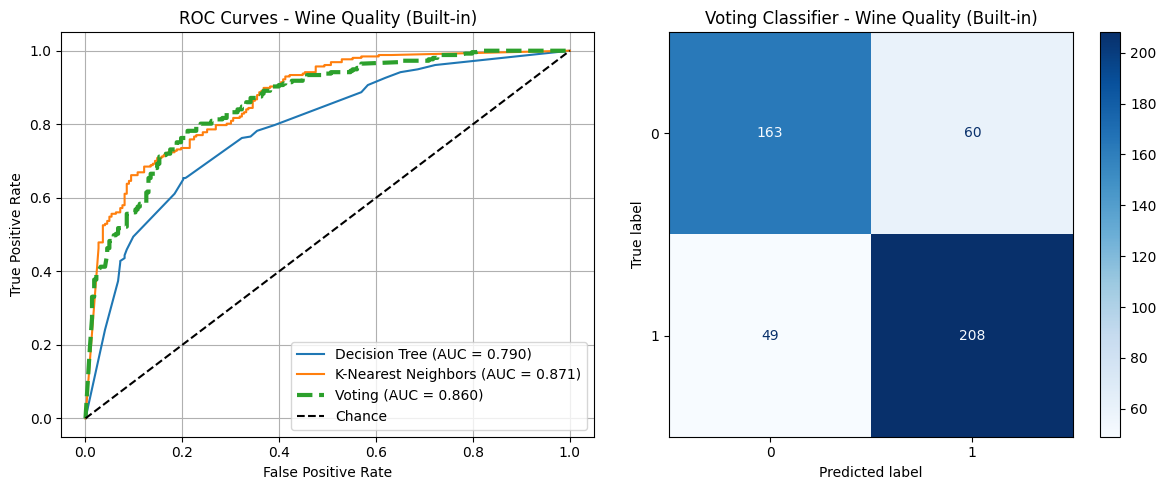


RUNNING RANDOMIZED SEARCH FOR WINE QUALITY

--- RandomizedSearchCV for Decision Tree ---
Execution Time: 1.16 seconds
Best params for Decision Tree: {'classifier__criterion': 'gini', 'classifier__max_depth': 6, 'classifier__min_samples_leaf': 8, 'feature_selection__k': 8, 'scaler': StandardScaler()}
Best CV score: 0.7880

--- RandomizedSearchCV for K-Nearest Neighbors ---
Execution Time: 1.20 seconds
Best params for K-Nearest Neighbors: {'classifier__metric': 'manhattan', 'classifier__n_neighbors': 14, 'classifier__weights': 'distance', 'feature_selection__k': 'all', 'scaler': MinMaxScaler()}
Best CV score: 0.8662

EVALUATING RANDOMIZED MODELS FOR WINE QUALITY

--- Individual Model Performance ---

Decision Tree:
  Accuracy: 0.7292
  Precision: 0.7326
  Recall: 0.7782
  F1-Score: 0.7547
  ROC AUC: 0.7950

K-Nearest Neighbors:
  Accuracy: 0.7896
  Precision: 0.7910
  Recall: 0.8249
  F1-Score: 0.8076
  ROC AUC: 0.8743

--- Randomized Voting Classifier ---
Voting Classifier Performance:

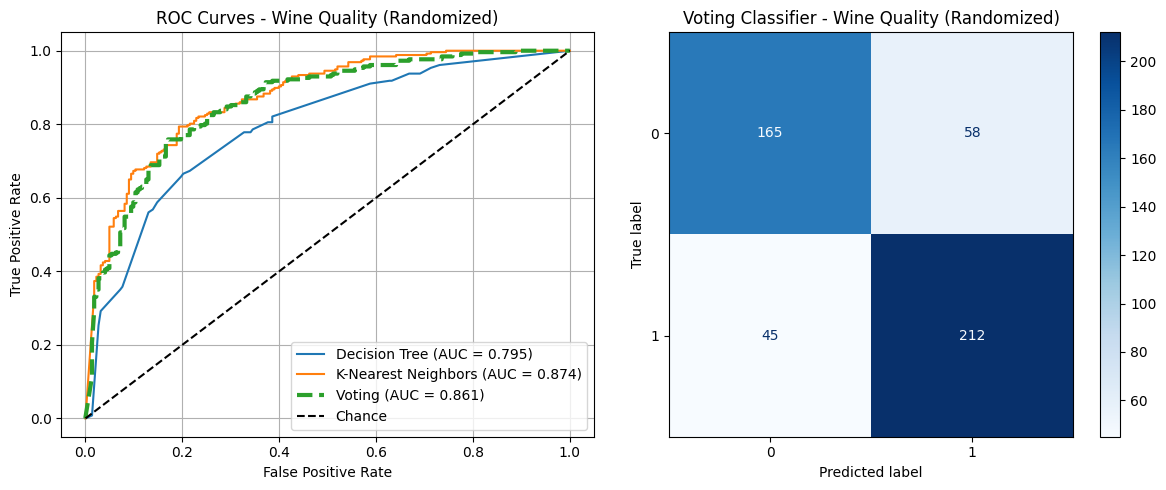


Completed processing for Wine Quality

################################################################################
PROCESSING DATASET: HR ATTRITION
################################################################################
HR Attrition dataset not found.
Skipping HR Attrition due to loading error.

################################################################################
PROCESSING DATASET: BANKNOTE AUTHENTICATION
################################################################################
------------------------------

RUNNING MANUAL GRID SEARCH FOR BANKNOTE AUTHENTICATION

--- Tuning Decision Tree ---
------------------------------------------------------------------------------------------
Best parameters for Decision Tree: {'scaler': StandardScaler(), 'feature_selection__k': 4, 'classifier__criterion': 'entropy', 'classifier__max_depth': 6, 'classifier__min_samples_leaf': 5}
Best cross-validation AUC: 0.9923

--- Tuning K-Nearest Neighbors ---
--------------

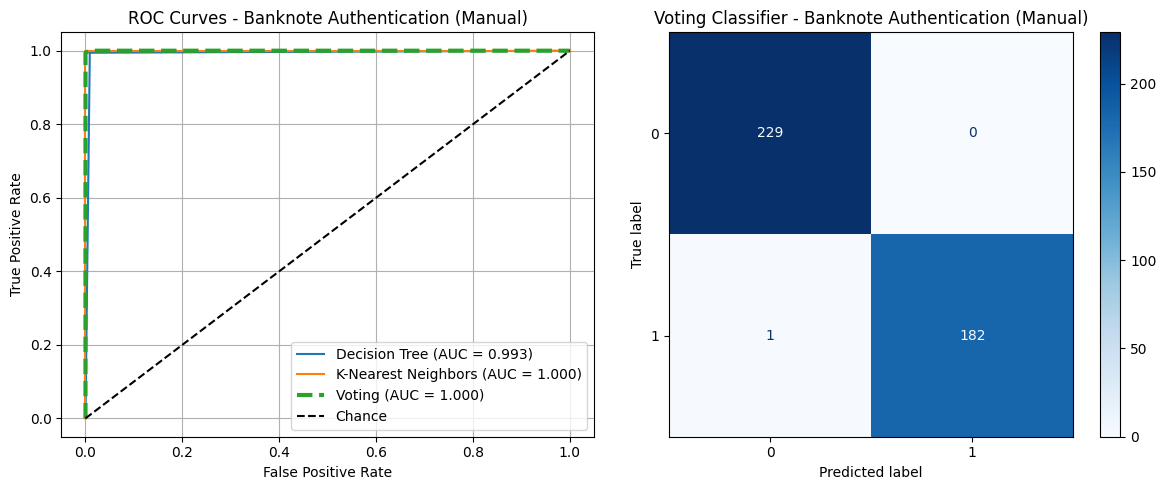


RUNNING BUILT-IN GRID SEARCH FOR BANKNOTE AUTHENTICATION

--- GridSearchCV for Decision Tree ---
Execution Time: 2.51 seconds
Best params for Decision Tree: {'classifier__criterion': 'entropy', 'classifier__max_depth': 6, 'classifier__min_samples_leaf': 5, 'feature_selection__k': 4, 'scaler': StandardScaler()}
Best CV score: 0.9923

--- GridSearchCV for K-Nearest Neighbors ---
Execution Time: 1.92 seconds
Best params for K-Nearest Neighbors: {'classifier__metric': 'manhattan', 'classifier__n_neighbors': 7, 'classifier__weights': 'distance', 'feature_selection__k': 4, 'scaler': StandardScaler()}
Best CV score: 0.9990

EVALUATING BUILT-IN MODELS FOR BANKNOTE AUTHENTICATION

--- Individual Model Performance ---

Decision Tree:
  Accuracy: 0.9927
  Precision: 0.9891
  Recall: 0.9945
  F1-Score: 0.9918
  ROC AUC: 0.9928

K-Nearest Neighbors:
  Accuracy: 1.0000
  Precision: 1.0000
  Recall: 1.0000
  F1-Score: 1.0000
  ROC AUC: 1.0000

--- Built-in Voting Classifier ---
Voting Classifier Per

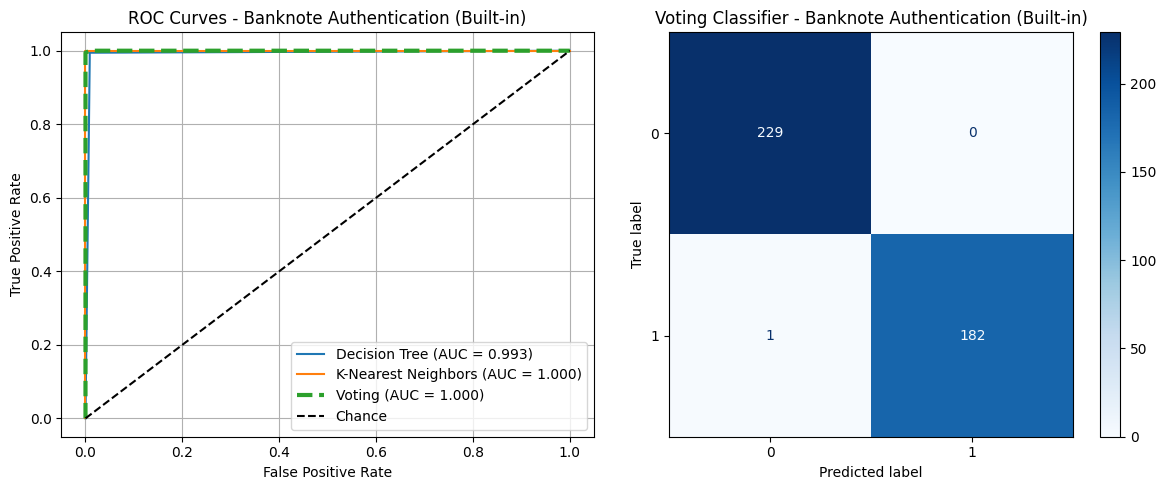


RUNNING RANDOMIZED SEARCH FOR BANKNOTE AUTHENTICATION

--- RandomizedSearchCV for Decision Tree ---
Execution Time: 0.84 seconds
Best params for Decision Tree: {'classifier__criterion': 'entropy', 'classifier__max_depth': 10, 'classifier__min_samples_leaf': 8, 'feature_selection__k': 'all', 'scaler': StandardScaler()}
Best CV score: 0.9917

--- RandomizedSearchCV for K-Nearest Neighbors ---
Execution Time: 0.48 seconds
Best params for K-Nearest Neighbors: {'classifier__metric': 'manhattan', 'classifier__n_neighbors': 7, 'classifier__weights': 'distance', 'feature_selection__k': 'all', 'scaler': MinMaxScaler()}
Best CV score: 0.9990

EVALUATING RANDOMIZED MODELS FOR BANKNOTE AUTHENTICATION

--- Individual Model Performance ---

Decision Tree:
  Accuracy: 0.9903
  Precision: 0.9838
  Recall: 0.9945
  F1-Score: 0.9891
  ROC AUC: 0.9903

K-Nearest Neighbors:
  Accuracy: 1.0000
  Precision: 1.0000
  Recall: 1.0000
  F1-Score: 1.0000
  ROC AUC: 1.0000

--- Randomized Voting Classifier ---
V

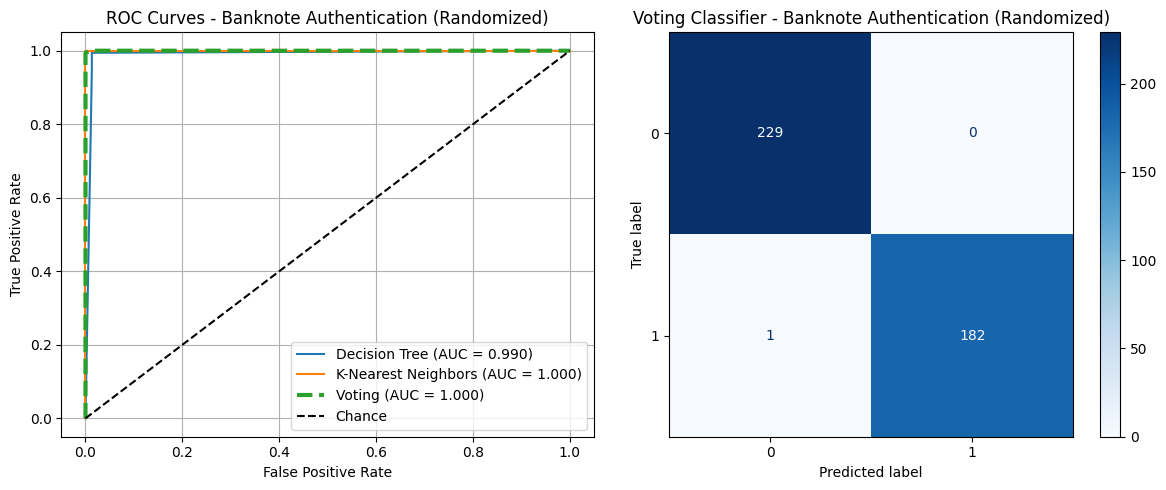


Completed processing for Banknote Authentication

################################################################################
PROCESSING DATASET: QSAR BIODEGRADATION
################################################################################
------------------------------

RUNNING MANUAL GRID SEARCH FOR QSAR BIODEGRADATION

--- Tuning Decision Tree ---
------------------------------------------------------------------------------------------
Best parameters for Decision Tree: {'scaler': StandardScaler(), 'feature_selection__k': 'all', 'classifier__criterion': 'entropy', 'classifier__max_depth': 5, 'classifier__min_samples_leaf': 3}
Best cross-validation AUC: 0.8628

--- Tuning K-Nearest Neighbors ---
------------------------------------------------------------------------------------------
Best parameters for K-Nearest Neighbors: {'scaler': MinMaxScaler(), 'feature_selection__k': 'all', 'classifier__n_neighbors': 7, 'classifier__weights': 'distance', 'classifier__metric': 'm

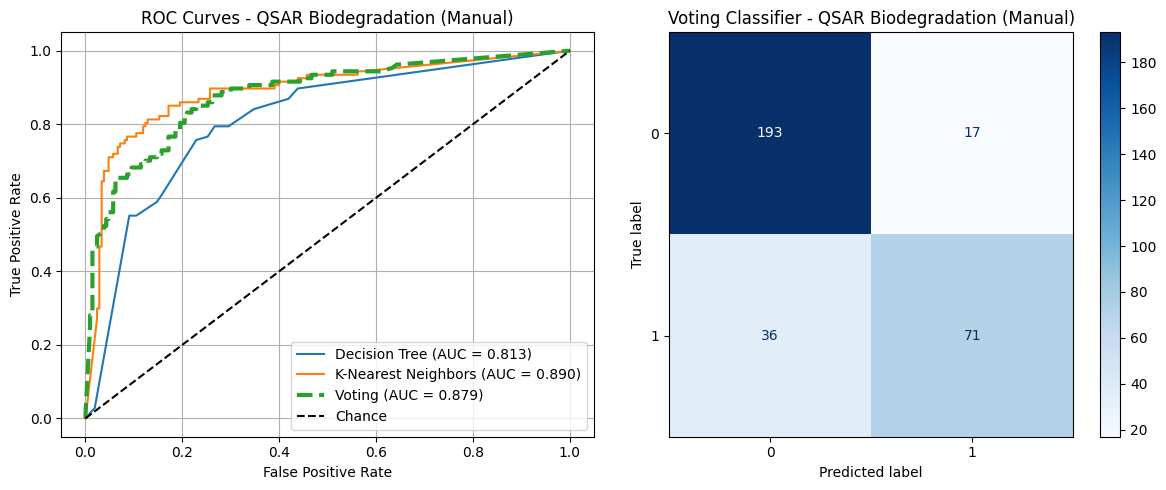


RUNNING BUILT-IN GRID SEARCH FOR QSAR BIODEGRADATION

--- GridSearchCV for Decision Tree ---
Execution Time: 4.79 seconds
Best params for Decision Tree: {'classifier__criterion': 'entropy', 'classifier__max_depth': 5, 'classifier__min_samples_leaf': 3, 'feature_selection__k': 'all', 'scaler': StandardScaler()}
Best CV score: 0.8628

--- GridSearchCV for K-Nearest Neighbors ---
Execution Time: 2.06 seconds
Best params for K-Nearest Neighbors: {'classifier__metric': 'manhattan', 'classifier__n_neighbors': 7, 'classifier__weights': 'distance', 'feature_selection__k': 'all', 'scaler': MinMaxScaler()}
Best CV score: 0.9033

EVALUATING BUILT-IN MODELS FOR QSAR BIODEGRADATION

--- Individual Model Performance ---

Decision Tree:
  Accuracy: 0.7666
  Precision: 0.6279
  Recall: 0.7570
  F1-Score: 0.6864
  ROC AUC: 0.8134

K-Nearest Neighbors:
  Accuracy: 0.8517
  Precision: 0.7830
  Recall: 0.7757
  F1-Score: 0.7793
  ROC AUC: 0.8905

--- Built-in Voting Classifier ---
Voting Classifier Perfo

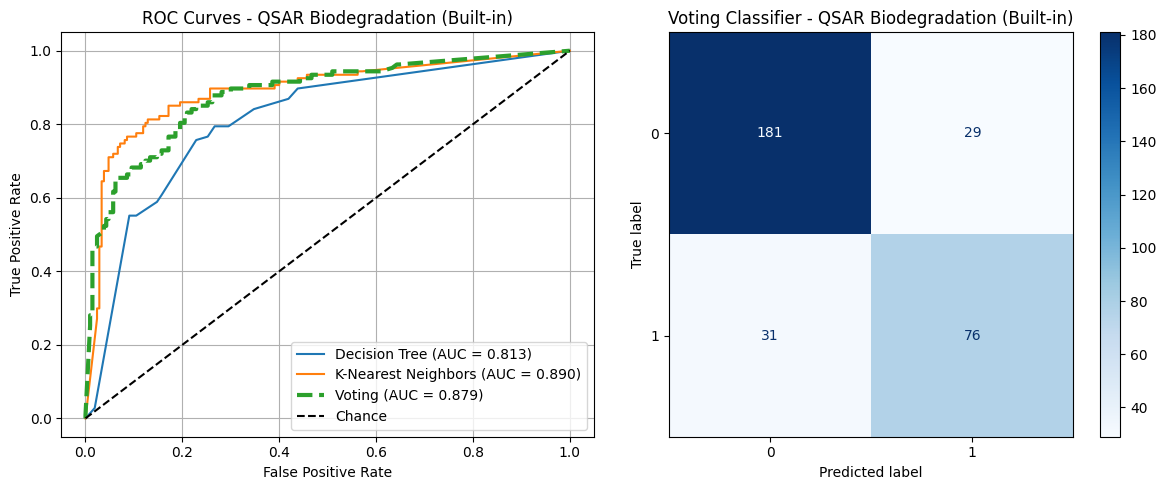


RUNNING RANDOMIZED SEARCH FOR QSAR BIODEGRADATION

--- RandomizedSearchCV for Decision Tree ---
Execution Time: 0.76 seconds
Best params for Decision Tree: {'classifier__criterion': 'gini', 'classifier__max_depth': 10, 'classifier__min_samples_leaf': 5, 'feature_selection__k': 'all', 'scaler': MinMaxScaler()}
Best CV score: 0.8416

--- RandomizedSearchCV for K-Nearest Neighbors ---
Execution Time: 0.60 seconds
Best params for K-Nearest Neighbors: {'classifier__metric': 'manhattan', 'classifier__n_neighbors': 14, 'classifier__weights': 'distance', 'feature_selection__k': 'all', 'scaler': MinMaxScaler()}
Best CV score: 0.9061

EVALUATING RANDOMIZED MODELS FOR QSAR BIODEGRADATION

--- Individual Model Performance ---

Decision Tree:
  Accuracy: 0.8013
  Precision: 0.6930
  Recall: 0.7383
  F1-Score: 0.7149
  ROC AUC: 0.8144

K-Nearest Neighbors:
  Accuracy: 0.8328
  Precision: 0.7368
  Recall: 0.7850
  F1-Score: 0.7602
  ROC AUC: 0.9062

--- Randomized Voting Classifier ---
Voting Classi

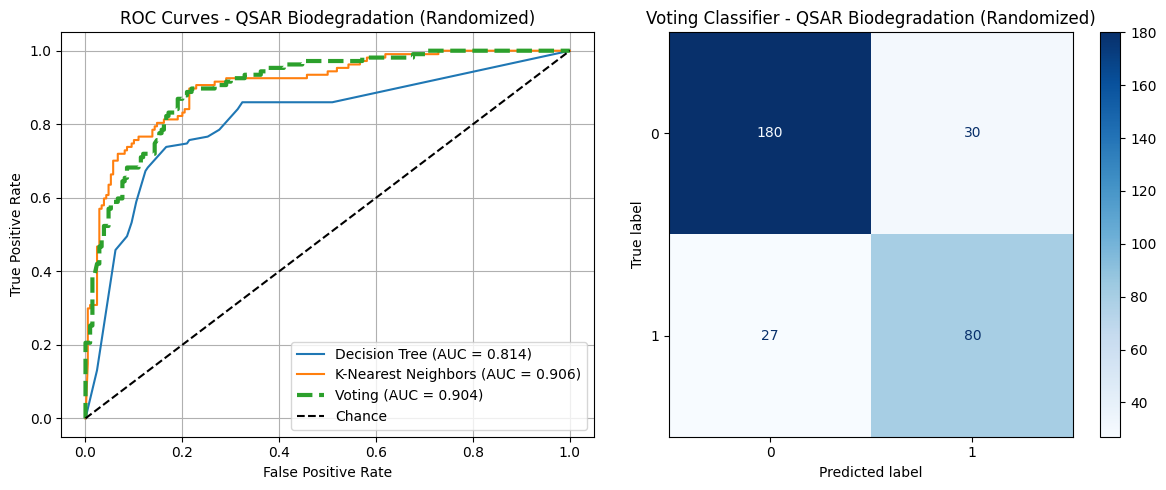


Completed processing for QSAR Biodegradation

ALL DATASETS PROCESSED!


In [ ]:
# --- Run Pipeline for All Datasets ---
datasets = [
    (load_wine_quality, "Wine Quality"),
    (load_hr_attrition, "HR Attrition"),
    (load_banknote, "Banknote Authentication"),
    (load_qsar_biodegradation, "QSAR Biodegradation")
]

# Run for each dataset
for dataset_loader, dataset_name in datasets:
    try:
        run_complete_pipeline(dataset_loader, dataset_name)
    except Exception as e:
        print(f"Error processing {dataset_name}: {e}")
        continue

print("\n" + "="*80)
print("ALL DATASETS PROCESSED!")
print("="*80)
